# Лабораторная работа №4 — задание 2

Проверяем условие

$$
\langle \nabla f(x^*),x-x^*\rangle\ge0
\qquad \forall x\in X
$$

и его координатные формы для параллелепипеда и неотрицательного орта.

In [1]:
import itertools
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize, linprog

TOL = 1e-8

## Условие (1.6) для параллелепипеда

Для

$$
X=\{x:a_j\le x_j\le b_j\}
$$

условие проверяется покоординатно:

- внутри интервала градиентная компонента равна нулю;
- на нижней границе она неотрицательна;
- на верхней границе она неположительна.

In [ ]:
def check_condition_1_6(grad, x, a, b, tol=TOL):
    grad = np.asarray(grad, dtype=float)
    x = np.asarray(x, dtype=float)
    a = np.asarray(a, dtype=float)
    b = np.asarray(b, dtype=float)

    at_lower = np.isclose(x, a, atol=tol, rtol=0)
    at_upper = np.isclose(x, b, atol=tol, rtol=0)
    interior = ~(at_lower | at_upper)

    return bool(
        np.all(np.abs(grad[interior]) <= tol)
        and np.all(grad[at_lower] >= -tol)
        and np.all(grad[at_upper] <= tol)
    )


def check_global_variational_condition(grad, x_star, lower, upper, tol=TOL):
    """Проверка min_{x in X} grad^T(x-x*) >= 0 через linprog."""
    result = linprog(c=grad, bounds=list(zip(lower, upper)), method="highs")

    if not result.success:
        return False, result.message

    min_value = result.fun - np.dot(grad, x_star)
    return min_value >= -tol, min_value


# Согласованность (1.6) и общей формулы на случайном примере
rng = np.random.default_rng(10)
a = np.array([-2.0, -1.0, 0.0])
b = np.array([1.0, 2.0, 3.0])
x = np.array([a[0], 0.5, b[2]])
grad = np.array([0.5, 0.0, -1.0])

print(check_condition_1_6(grad, x, a, b))
print(check_global_variational_condition(grad, x, a, b))

True
(np.True_, np.float64(0.0))


## Условие (1.7)–(1.8) для неотрицательного орта

Для

$$
X=\{x:x_j\ge0,\ j=1,\ldots,s\}:
$$

$$
\nabla_j f(x^*)\ge0,\qquad
x_j^*\nabla_j f(x^*)=0,\qquad j\le s,
$$

а для свободных координат:

$$
\nabla_j f(x^*)=0,\qquad j>s.
$$

In [ ]:
def check_condition_1_7(grad, x, s, tol=TOL):
    grad = np.asarray(grad, dtype=float)
    x = np.asarray(x, dtype=float)

    constrained = slice(0, s)
    free = slice(s, None)

    return bool(
        np.all(grad[constrained] >= -tol)
        and np.all(np.abs(x[constrained] * grad[constrained]) <= tol)
        and np.all(np.abs(grad[free]) <= tol)
    )


check_condition_1_7(grad, x, 2)

False

## Задача 2.2: квадратичная функция

$$
f(x)=2x_1^2+x_1x_2+x_2^2,
\qquad
-1\le x_1\le1,\qquad x_2\ge2.
$$

Градиент:

$$
\nabla f(x)=
\begin{pmatrix}
4x_1+x_2\\
x_1+2x_2
\end{pmatrix}.
$$

In [ ]:
H = np.array([[4.0, 1.0], [1.0, 2.0]])


def f_quadratic(x):
    x1, x2 = x
    return 2 * x1**2 + x1 * x2 + x2**2


def grad_quadratic(x):
    return H @ x


def active_set_candidates():
    candidates = []

    for status_x1, status_x2 in itertools.product(
        ("lower", "free", "upper"), ("lower", "free")
    ):
        status = (status_x1, status_x2)
        x = np.zeros(2)
        fixed = {}
        free_indices = []

        if status_x1 == "lower":
            fixed[0] = -1.0
        elif status_x1 == "upper":
            fixed[0] = 1.0
        else:
            free_indices.append(0)

        if status_x2 == "lower":
            fixed[1] = 2.0
        else:
            free_indices.append(1)

        for i, value in fixed.items():
            x[i] = value

        if free_indices:
            F = np.array(free_indices)
            A = H[np.ix_(F, F)]
            rhs = np.zeros(len(F))
            for i, value in fixed.items():
                rhs -= H[np.ix_(F, [i])].ravel() * value
            x[F] = np.linalg.solve(A, rhs)

        grad = grad_quadratic(x)
        feasible = -1 - TOL <= x[0] <= 1 + TOL and x[1] >= 2 - TOL

        kkt = True
        if status_x1 == "lower":
            kkt &= grad[0] >= -TOL
        if status_x1 == "upper":
            kkt &= grad[0] <= TOL
        if status_x2 == "lower":
            kkt &= grad[1] >= -TOL
        for i in free_indices:
            kkt &= abs(grad[i]) <= TOL

        candidates.append(
            {
                "active_set": status,
                "x": x,
                "grad": grad,
                "feasible": feasible,
                "satisfies_condition": bool(kkt and feasible),
            }
        )

    return candidates


candidates = active_set_candidates()

for candidate in candidates:
    print(candidate["active_set"], candidate["x"], candidate["satisfies_condition"])

valid = [c["x"] for c in candidates if c["satisfies_condition"]]
print("Кандидаты, удовлетворяющие условию:", valid)

('lower', 'lower') [-1.  2.] False
('lower', 'free') [-1.   0.5] False
('free', 'lower') [-0.5  2. ] True
('free', 'free') [0. 0.] False
('upper', 'lower') [1. 2.] False
('upper', 'free') [ 1.  -0.5] False
Кандидаты, удовлетворяющие условию: [array([-0.5,  2. ])]


In [ ]:
result = minimize(
    f_quadratic,
    x0=np.array([0.0, 3.0]),
    jac=grad_quadratic,
    method="SLSQP",
    bounds=[(-1.0, 1.0), (None, None)],
    constraints={"type": "ineq", "fun": lambda x: x[1] - 2.0},
    options={"ftol": 1e-12, "maxiter": 500},
)

print(result.x)
print(result.fun)
print(result.message)

[-0.5  2. ]
3.500000000000006
Optimization terminated successfully


Ожидаемый оптимум:

$$
\boxed{x^*=(-1/2,\,2)}.
$$

Он совпадает с активным перебором и численным решением SciPy.

## Задача 2.3: лемма для неотрицательного орта

$$
f(x)=\frac12\|x\|^2-\langle c,x\rangle,
\qquad x\ge0.
$$

Аналитическое решение:

$$
\boxed{x_j^*=\max(c_j,0)}.
$$

In [6]:
def analytic_solution(c):
    return np.maximum(c, 0.0)


def quadratic_orthant_objective(x, c):
    return 0.5 * np.dot(x, x) - np.dot(c, x)


def quadratic_orthant_gradient(x, c):
    return x - c


rng = np.random.default_rng(123)

for n in (1, 2, 5):
    c = rng.normal(size=n)
    x_star = analytic_solution(c)

    result = minimize(
        quadratic_orthant_objective,
        x0=np.zeros(n),
        args=(c,),
        jac=quadratic_orthant_gradient,
        method="L-BFGS-B",
        bounds=[(0.0, None)] * n,
    )

    print(f"n={n}")
    print("c       =", c)
    print("formula =", x_star)
    print("SciPy   =", result.x)
    print("error   =", np.linalg.norm(x_star - result.x))
    print()

n=1
c       = [-0.98912135]
formula = [0.]
SciPy   = [0.]
error   = 0.0

n=2
c       = [-0.36778665  1.28792526]
formula = [0.         1.28792526]
SciPy   = [0.         1.28792526]
error   = 0.0

n=5
c       = [ 0.19397442  0.9202309   0.57710379 -0.63646365  0.54195222]
formula = [0.19397442 0.9202309  0.57710379 0.         0.54195222]
SciPy   = [0.19397442 0.9202309  0.57710379 0.         0.54195222]
error   = 0.0



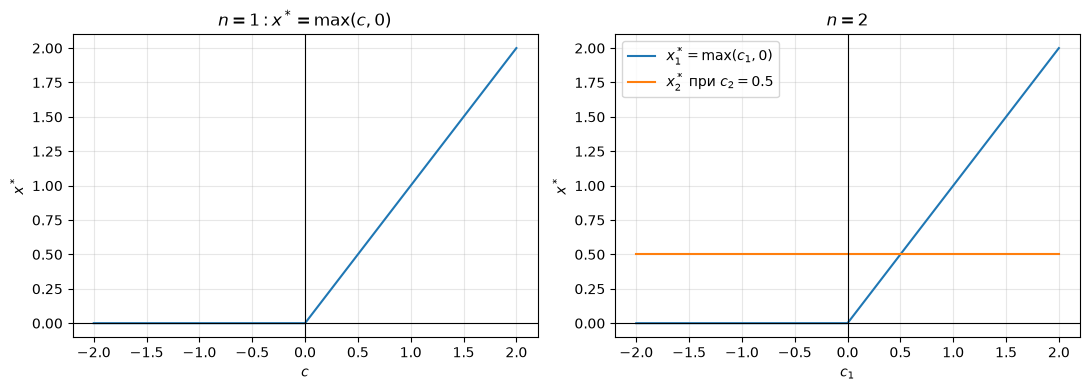

In [7]:
c_values = np.linspace(-2, 2, 400)

x_star_n1 = np.maximum(c_values, 0.0)

c_fixed = 0.5
x1_n2 = np.maximum(c_values, 0.0)
x2_n2 = np.full_like(c_values, np.maximum(c_fixed, 0.0))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].plot(c_values, x_star_n1)
axes[0].axhline(0, color="black", linewidth=0.8)
axes[0].axvline(0, color="black", linewidth=0.8)
axes[0].set_title(r"$n=1: x^*=\max(c,0)$")
axes[0].set_xlabel("$c$")
axes[0].set_ylabel("$x^*$")
axes[0].grid(alpha=0.3)

axes[1].plot(c_values, x1_n2, label=r"$x_1^*=\max(c_1,0)$")
axes[1].plot(c_values, x2_n2, label=r"$x_2^*$ при $c_2=0.5$")
axes[1].axhline(0, color="black", linewidth=0.8)
axes[1].axvline(0, color="black", linewidth=0.8)
axes[1].set_title(r"$n=2$")
axes[1].set_xlabel("$c_1$")
axes[1].set_ylabel("$x^*$")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()